# Final Notebook 03 — Daily CHIRPS v3 RNL calibration and rolling-origin validation

**PH3043 · University of Colombo · Six Sri Lankan gauge stations · 1981–1994 model development**

**Research question (daily component):** *Which calibration approach can improve CHIRPS v3 RNL daily rainfall estimates without substantially degrading wet-day detection, heavy-rainfall representation or monthly accumulations?*

**Prior evidence:** Notebook 01 found that simple linear calibration can lower daily RMSE while causing excess predicted wet days and worse monthly totals. Notebook 02 found raw CHIRPS v3 RNL generally has lower daily RMSE than v2; temporal aggregation improves association, but buffering is not universally beneficial. This notebook evaluates **new daily corrections** and keeps v2/v3 as uncorrected references.

**Not a forecast:** We use *same-day* CHIRPS v3 RNL as an input to estimate *same-day* gauge rainfall, retrospectively. Do not describe these outputs as forecasts available before the CHIRPS product is released.

### Hypotheses

- **D1 (baseline):** A calibrated v3 model lowers development-period validation RMSE relative to raw v3.
- **D2 (occurrence):** Modelling rainfall occurrence and positive intensity separately can reduce false rain compared with a simple intercept-based correction.
- **D3 (seasonality):** Smooth annual/semiannual seasonal features improve validation compared with a rainfall-only correction.
- **D4 (trade-offs):** A lower all-day RMSE need not improve heavy-event error or accumulated monthly-total error.

These are questions to evaluate; no model is guaranteed to improve. **No model is selected using 1995–2000.**

In [21]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
Using cached statsmodels-0.15.0-cp311-cp311-win_amd64.whl (11.4 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)

   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------

## 0 · Reproducibility, folders and date protocol

No additional Google Earth Engine export is needed. We reuse the matched point-sampling CSV from Final Notebooks 01/02. Locate the project root automatically from `notebooks/Final_Notebooks/`, and save outputs under `results/Final_03_Daily_Calibration/run_###` so existing outputs are not overwritten.

The original lab brief asks for a simple training-only correction and independent chronological validation; Notebook 01 did that. This notebook adds *expanding-window* development evaluation.

| Fold | Train on dates | Validate on dates |
|---|---|---|
| 1 | 1981–1986 | 1987–1988 |
| 2 | 1981–1988 | 1989–1990 |
| 3 | 1981–1990 | 1991–1992 |
| 4 | 1981–1992 | 1993–1994 |

The historically explored **1995–2000** period is intentionally **not loaded into model development** in this notebook. Notation: `G` = gauge precipitation (mm/day); `S` = CHIRPS precipitation (mm/day); all comparisons use identical matched station–dates.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, GammaRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

warnings.filterwarnings("ignore", category=ConvergenceWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

cwd = Path.cwd().resolve()
roots = [cwd, *cwd.parents, Path('/mnt/data')]
PROJECT_ROOT = next((r for r in roots if (r/'data').is_dir() and (r/'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    # Jupyter is usually launched with cwd = project/notebooks/Final_Notebooks.
    PROJECT_ROOT = cwd if (cwd == Path('/mnt/data') or (cwd/'Ground_CHIRPS_V2_V3_Paired_1981_2000.xls').is_file()) else cwd.parent.parent

FILENAME = 'Ground_CHIRPS_V2_V3_Paired_1981_2000.csv'
DATA_PATH = next((p for p in [PROJECT_ROOT/'data'/'processed'/FILENAME,
                            PROJECT_ROOT/'data'/'processed'/FILENAME.replace('.csv','.xls'),
                            Path('/mnt/data')/FILENAME,
                            Path('/mnt/data')/FILENAME.replace('.csv','.xls')]
                  if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Set DATA_PATH to the paired daily CSV in data/processed/. No new extraction needed.')

BASE = PROJECT_ROOT/'results'/'Final_03_Daily_Calibration'
run_id = 1
while (BASE/f'run_{run_id:03d}').exists():
    run_id += 1
OUTPUT = BASE/f'run_{run_id:03d}'
FIGDIR = OUTPUT/'figures'; TABDIR = OUTPUT/'tables'
FIGDIR.mkdir(parents=True, exist_ok=False)
TABDIR.mkdir(parents=True, exist_ok=False)
STATIONS = ['Badulla','Colombo','Galle','Kandy','Nuwaraeliya','Puttalam']
WET_THRESHOLD = 1.0    # mm/day; lab-sheet recommended wet-day threshold
HEAVY_THRESHOLD = 25.0 # mm/day; descriptive gauge-defined heavy days
FOLDS = [(('1981-01-01','1986-12-31'),('1987-01-01','1988-12-31')),
         (('1981-01-01','1988-12-31'),('1989-01-01','1990-12-31')),
         (('1981-01-01','1990-12-31'),('1991-01-01','1992-12-31')),
         (('1981-01-01','1992-12-31'),('1993-01-01','1994-12-31'))]
print('Data:', DATA_PATH)
print('Output:', OUTPUT)
print('Historical 1995–2000 target rows are excluded from model development.')

Data: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_V2_V3_Paired_1981_2000.csv
Output: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_03_Daily_Calibration\run_001
Historical 1995–2000 target rows are excluded from model development.


## 1 · Load and audit daily data

Check that `Date` is parsed, that each station–date is unique, and that both versions have finite nonnegative values. We do **not** replace missing observations with zero or infer unknown rain-trace measurement magnitudes. The source may encode trace as zero; keep its QC flag for auditing.

In [3]:
raw = pd.read_csv(DATA_PATH)
required = {'Date','Station','Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm'}
assert required.issubset(raw.columns), f'Missing columns: {required-set(raw.columns)}'
raw['Date'] = pd.to_datetime(raw['Date'], errors='raise')
assert not raw.duplicated(['Station','Date']).any(), 'Duplicate station-date pairs!'
raw = raw.loc[raw['Station'].isin(STATIONS)].copy()
for col in ['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']:
    raw[col] = pd.to_numeric(raw[col], errors='coerce')
valid = raw[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']].notna().all(axis=1) & (raw[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']] >= 0).all(axis=1)
raw = raw.loc[valid].sort_values(['Station','Date']).reset_index(drop=True)
dev = raw.loc[raw.Date.between('1981-01-01','1994-12-31')].copy()
assert dev.Date.max() <= pd.Timestamp('1994-12-31')
coverage = dev.groupby('Station').agg(n_dev=('Date','size'),first=('Date','min'),last=('Date','max')).reindex(STATIONS)
display(coverage)
print(f'Entire paired data rows: {len(raw):,}; development rows: {len(dev):,}; station count: {dev.Station.nunique()}')
if 'QC_Flag' in raw: display(raw['QC_Flag'].value_counts(dropna=False).rename('rows'))
coverage.to_csv(TABDIR/'01_development_coverage.csv')

,n_dev,first,last
Station,,,
Badulla,5109,1981-01-01,1994-12-31
Colombo,5088,1981-01-01,1994-12-31
Galle,5099,1981-01-01,1994-12-31
Kandy,5106,1981-01-01,1994-12-31
Nuwaraeliya,5098,1981-01-01,1994-12-31
Puttalam,5103,1981-01-01,1994-12-31


Entire paired data rows: 43,737; development rows: 30,603; station count: 6


QC_Flag
Valid    43182
Trace      555
Name: rows, dtype: int64

## 2 · Reusable metrics and plotting utilities

**Daily amount metrics** (all station-date pairs shared by all models):

\[\mathrm{Bias}=N^{-1}\sum_i(\hat G_i-G_i),\quad \mathrm{MAE}=N^{-1}\sum_i |\hat G_i-G_i|,\quad \mathrm{RMSE}=\sqrt{N^{-1}\sum_i(\hat G_i-G_i)^2}.\]

**Occurrence:** wet day ≥1 mm/day; `POD = H/(H+M)`, `FAR = F/(H+F)`, `CSI = H/(H+M+F)`; undefined denominators yield NaN, never zero by assumption.

**Gauge-defined heavy-day RMSE:** evaluate error on days with *observed* ≥25 mm/day. This is not an extreme-event detection score and should not be used to tune a model on test data.

**Monthly-total RMSE** uses only *complete calendar months* of out-of-fold predictions; monthly totals use mm/month, not mm/day.

In [5]:
def save_figure(fig, name):
    """Save the supplied Matplotlib figure as print and vector versions."""
    for ext in ['png','pdf']:
        fig.savefig(FIGDIR/f'{name}.{ext}', dpi=250, bbox_inches='tight')

def safe_ratio(a, b):
    return float(a/b) if b else np.nan

def rainfall_scores(gauge, predicted):
    g = np.asarray(gauge, dtype=float); p = np.asarray(predicted, dtype=float)
    mask = np.isfinite(g) & np.isfinite(p) & (g >= 0) & (p >= 0)
    g = g[mask]; p = p[mask]; e = p-g
    if len(g)==0: return dict(n=0,RMSE=np.nan,MAE=np.nan,Bias=np.nan,Pearson_r=np.nan,Spearman_rho=np.nan)
    return {'n':int(len(g)), 'RMSE':float(np.sqrt(np.mean(e**2))),
            'MAE':float(np.mean(np.abs(e))), 'Bias':float(e.mean()),
            'Pearson_r':float(pd.Series(g).corr(pd.Series(p), method='pearson')) if np.std(g)>0 and np.std(p)>0 else np.nan,
            'Spearman_rho':float(pd.Series(g).corr(pd.Series(p), method='spearman')) if len(np.unique(g))>1 and len(np.unique(p))>1 else np.nan}

def wetday_scores(gauge, predicted, threshold=WET_THRESHOLD):
    g = np.asarray(gauge, float)>=threshold; p = np.asarray(predicted,float)>=threshold
    H = int(np.sum(g&p)); M = int(np.sum(g&~p)); F=int(np.sum(~g&p)); C=int(np.sum(~g&~p))
    return {'Hits':H,'Misses':M,'False_alarms':F,'Correct_negatives':C,
            'POD':safe_ratio(H,H+M),'FAR':safe_ratio(F,H+F),'CSI':safe_ratio(H,H+M+F)}

def heavy_scores(gauge, predicted, threshold=HEAVY_THRESHOLD):
    g=np.asarray(gauge,float); p=np.asarray(predicted,float); ix=g>=threshold
    return {'n_heavy':int(ix.sum()),
            'Heavy_RMSE':float(np.sqrt(np.mean((p[ix]-g[ix])**2))) if ix.any() else np.nan,
            'Heavy_Bias':float((p[ix]-g[ix]).mean()) if ix.any() else np.nan}

def complete_month_scores(pred):
    """Results for complete months within each station/model/fold only."""
    d=pred.copy();d['Month']=d.Date.dt.to_period('M').dt.to_timestamp()
    m=d.groupby(['Fold','Station','Model','Month'],as_index=False).agg(
        n=('Date','nunique'), Gauge_total=('Gauge_mm_day','sum'), Pred_total=('Prediction_mm_day','sum'))
    m=m.loc[m.n.eq(m.Month.dt.days_in_month)].copy()
    rows=[]
    for (s,model),a in m.groupby(['Station','Model']):
        sc=rainfall_scores(a.Gauge_total,a.Pred_total)
        rows.append({'Station':s,'Model':model,'n_complete_months':len(a),
                     'Monthly_RMSE_mm_month':sc['RMSE'],'Monthly_Bias_mm_month':sc['Bias'],
                     'Monthly_Pearson_r':sc['Pearson_r']})
    return m, pd.DataFrame(rows)

def plot_metric_dotplot(scores, metric='RMSE', models=None, title=None, save_as=None):
    """Station-by-model dot plot for an already computed summary table."""
    dd=scores.copy()
    if models is not None: dd=dd[dd.Model.isin(models)]
    fig,ax=plt.subplots(figsize=(9,5.5))
    for model,group in dd.groupby('Model',sort=False):
        y=[STATIONS.index(s) for s in group.Station]
        ax.scatter(group[metric],y,label=model,s=55)
    ax.set_yticks(range(len(STATIONS)),[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set_xlabel('Daily RMSE (mm/day)' if metric=='RMSE' else metric)
    ax.set_title(title or 'Rolling-origin pooled out-of-fold evaluation')
    ax.grid(axis='x',alpha=.2);ax.legend(fontsize=8,ncol=2)
    fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_station_predictions(pred, station='Kandy', start='1993-01-01', end='1993-03-31', models=None, save_as=None):
    ss=pred[(pred.Station==station)&pred.Date.between(start,end)].copy()
    if models: ss=ss[ss.Model.isin(models)]
    fig,ax=plt.subplots(figsize=(11,4))
    gauge=ss.groupby('Date',as_index=False).Gauge_mm_day.first()
    ax.plot(gauge.Date,gauge.Gauge_mm_day,color='black',lw=1.5,label='Gauge')
    for model,d in ss.groupby('Model'):
        ax.plot(d.Date,d.Prediction_mm_day,lw=1.15,alpha=.85,label=model)
    ax.set(title=f'{station}: daily rainfall (out-of-fold)',ylabel='Rainfall (mm/day)',xlabel='Date')
    ax.legend(ncol=3,fontsize=8);ax.grid(alpha=.2);fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

## 3 · Candidate daily calibration models and their physical meanings

Use **same-day v3 RNL precipitation** as the common input. For fairness, the raw v2 and v3 baselines are included on the same dates.

1. **Raw v2 / raw v3:** No learned coefficients; reference models.
2. **Linear v3:** \(\hat G = \max(0,a+bS)\). Fitted by ordinary least squares. Can create false drizzle through a positive intercept.
3. **Multiplicative v3:** \(\hat G = cS\), where \(c=\sum G/\sum S\) calculated on *training data only*. Preserves raw zero-rain predictions but may worsen individual extremes.
4. **Seasonal Ridge v3:** \(\hat G=\max[0, a+\beta^T \boldsymbol x]\), with \(\boldsymbol x=[S,\sin(2\pi d/365.2425),\cos(2\pi d/365.2425),\sin(4\pi d/365.2425),\cos(4\pi d/365.2425)]\). Select a **fixed** Ridge penalty here; comparing multiple penalties belongs in a nested validation procedure.
5. **Hurdle v3:** Logistic regression estimates probability of *measurable wet day* \(P(G\geq1\mid S,d)\), and Gamma GLM estimates positive rainfall intensity \(\mathbb E[G\mid G\geq1,S,d]\). Their product gives an **expected daily amount**, not a binary wet-day prediction. For occurrence classification, a separate \(P\geq0.5\) threshold is used. Gamma is trained only on observations ≥1 mm/day, a positive response.

**Important:** For the hurdle model, report magnitude metrics using expected amount \(p\mu\), **but use the logistic probability for wet-day classification**, not `p*mu >= 1`. This avoids mixing two different decision rules.

All transformations are trained anew within each fold; no station's validation gauge data are used in fitting. Negative predicted rainfall is clipped to zero. No hyperparameters are selected using 1995–2000.

In [7]:
def seasonal_features(df):
    """Same-day CHIRPS v3 plus deterministic calendar features."""
    doy=df.Date.dt.dayofyear.to_numpy(float)
    theta=2*np.pi*(doy-1)/365.2425
    s=df.CHIRPS_V3_mm.to_numpy(float)
    return np.column_stack([s,np.sin(theta),np.cos(theta),np.sin(2*theta),np.cos(2*theta)])

def train_calibrator(model_name, training):
    """Fit one model on the supplied training rows only."""
    s=training.CHIRPS_V3_mm.to_numpy(float)
    g=training.Rainfall_mm.to_numpy(float)
    if model_name in ('Raw v2','Raw v3'):
        return {'name':model_name}
    if model_name=='Multiplicative v3':
        factor=float(g.sum()/s.sum()) if s.sum()>0 else 1.0
        return {'name':model_name,'factor':factor}
    if model_name=='Linear v3':
        estimator=LinearRegression().fit(s.reshape(-1,1),g)
        return {'name':model_name,'estimator':estimator,
                'intercept':float(estimator.intercept_),'slope':float(estimator.coef_[0])}
    X=seasonal_features(training)
    if model_name=='Seasonal Ridge v3':
        estimator=make_pipeline(StandardScaler(),Ridge(alpha=100.0))
        estimator.fit(X,g)
        return {'name':model_name,'estimator':estimator}
    if model_name=='Hurdle v3':
        wet=(g>=WET_THRESHOLD).astype(int)
        if len(np.unique(wet))<2:
            raise ValueError('Need both wet and dry days to fit logistic occurrence.')
        occ=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,C=1.0))
        occ.fit(X,wet)
        positive=(g>=WET_THRESHOLD)
        intensity=make_pipeline(StandardScaler(), GammaRegressor(alpha=1.0,max_iter=500,tol=1e-5))
        intensity.fit(X[positive],g[positive])
        return {'name':model_name,'occ':occ,'intensity':intensity}
    raise ValueError(f'Unknown model: {model_name}')

def predict_calibrator(fit, rows):
    """Return amount predictions, and separately occurrence probabilities when available."""
    name=fit['name']; s=rows.CHIRPS_V3_mm.to_numpy(float)
    if name=='Raw v2': return rows.CHIRPS_mm.to_numpy(float),None
    if name=='Raw v3': return s,None
    if name=='Multiplicative v3':return fit['factor']*s,None
    if name=='Linear v3':
        return np.maximum(0,fit['estimator'].predict(s.reshape(-1,1))),None
    X=seasonal_features(rows)
    if name=='Seasonal Ridge v3':return np.maximum(0,fit['estimator'].predict(X)),None
    if name=='Hurdle v3':
        prob=fit['occ'].predict_proba(X)[:,1]
        intensity=np.maximum(0,fit['intensity'].predict(X))
        return prob*intensity,prob
    raise ValueError(name)

MODELS=['Raw v2','Raw v3','Linear v3','Multiplicative v3','Seasonal Ridge v3','Hurdle v3']
print('Candidate models:', ', '.join(MODELS))

Candidate models: Raw v2, Raw v3, Linear v3, Multiplicative v3, Seasonal Ridge v3, Hurdle v3


## 4 · Four-fold expanding-window validation

The evaluation uses *out-of-fold predictions*: every scored day is later than all training days in its fold. We retain all candidate outputs rather than choosing the winner from an individual good-looking interval.

**Why no XGBoost yet?** We first establish whether simple models generalize. A nonlinear model would need a separate, controlled, training-only hyperparameter procedure; its inclusion is not required to satisfy the daily-calibration objective.

In [9]:
prediction_parts=[]; fitted_parameters=[]
for fold, (train_dates, val_dates) in enumerate(FOLDS,1):
    tr=dev.loc[dev.Date.between(*train_dates)]
    va=dev.loc[dev.Date.between(*val_dates)]
    assert tr.Date.max()<va.Date.min()
    print(f'Fold {fold}: train {train_dates[0]}–{train_dates[1]}, validate {val_dates[0]}–{val_dates[1]}')
    for station in STATIONS:
        tr_s=tr.loc[tr.Station==station]
        va_s=va.loc[va.Station==station]
        for name in MODELS:
            fit=train_calibrator(name,tr_s)
            amount,prob=predict_calibrator(fit,va_s)
            part=pd.DataFrame({'Fold':fold,'Date':va_s.Date.to_numpy(),
                               'Station':station,'Model':name,
                               'Gauge_mm_day':va_s.Rainfall_mm.to_numpy(float),
                               'Prediction_mm_day':amount,
                               'Wet_probability': prob if prob is not None else np.full(len(va_s),np.nan)})
            prediction_parts.append(part)
            fitted_parameters.append({'Fold':fold,'Station':station,'Model':name,
                                      'Train_start':train_dates[0],'Train_end':train_dates[1],
                                      'Validate_start':val_dates[0],'Validate_end':val_dates[1],
                                      'Train_n':len(tr_s),'Validate_n':len(va_s),
                                      'Linear_intercept':fit.get('intercept',np.nan),
                                      'Linear_slope':fit.get('slope',np.nan),
                                      'Multiplicative_factor':fit.get('factor',np.nan)})
predictions=pd.concat(prediction_parts,ignore_index=True)
parameters=pd.DataFrame(fitted_parameters)
assert predictions.Date.max()<=pd.Timestamp('1994-12-31')
assert not predictions.duplicated(['Date','Station','Model']).any()
# All models must have the same date keys for each station
assert predictions.groupby(['Station','Model']).size().groupby(level=0).nunique().eq(1).all()
predictions.to_csv(TABDIR/'02_daily_out_of_fold_predictions.csv',index=False)
parameters.to_csv(TABDIR/'03_fold_training_parameters.csv',index=False)
print('Out-of-fold prediction rows:', len(predictions))
display(parameters.loc[parameters.Model.isin(['Linear v3','Multiplicative v3'])].head(12).round(3))

Fold 1: train 1981-01-01–1986-12-31, validate 1987-01-01–1988-12-31
Fold 2: train 1981-01-01–1988-12-31, validate 1989-01-01–1990-12-31
Fold 3: train 1981-01-01–1990-12-31, validate 1991-01-01–1992-12-31
Fold 4: train 1981-01-01–1992-12-31, validate 1993-01-01–1994-12-31
Out-of-fold prediction rows: 104856


,Fold,Station,Model,Train_start,Train_end,Validate_start,Validate_end,Train_n,Validate_n,Linear_intercept,Linear_slope,Multiplicative_factor
2,1,Badulla,Linear v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2191,729,1.819,0.652,NaN
3,1,Badulla,Multiplicative v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2191,729,NaN,NaN,1.041
8,1,Colombo,Linear v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2191,719,0.905,0.733,NaN
9,1,Colombo,Multiplicative v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2191,719,NaN,NaN,0.877
14,1,Galle,Linear v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2186,731,2.548,0.513,NaN
15,1,Galle,Multiplicative v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2186,731,NaN,NaN,0.934
20,1,Kandy,Linear v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2185,730,2.270,0.539,NaN
21,1,Kandy,Multiplicative v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2185,730,NaN,NaN,0.992
26,1,Nuwaraeliya,Linear v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2183,730,1.780,0.644,NaN
27,1,Nuwaraeliya,Multiplicative v3,1981-01-01,1986-12-31,1987-01-01,1988-12-31,2183,730,NaN,NaN,0.991


## 5 · Daily RMSE/MAE/bias, wet-day skill and heavy rainfall

Models are compared on the **same out-of-fold station-days**, which allows paired comparisons. For `Hurdle v3`, wet-day skill is computed from the probability threshold 0.5; this is a fixed decision rule, **not tuned on validation**. All other models use the ≥1 mm/day amount threshold.

Do not interpret the *lowest validation RMSE* as automatically the best model for rainfall occurrence, extremes and monthly totals.

,Station,Model,n,RMSE,MAE,Bias,Pearson_r,POD,FAR,CSI,n_heavy,Heavy_RMSE,RMSE_improvement_percent
0,Badulla,Raw v2,2918,12.027,5.631,-0.177,0.412,0.478,0.414,0.357,163,35.093,-6.610
1,Badulla,Raw v3,2918,11.281,5.430,0.229,0.413,0.795,0.476,0.462,163,35.982,0.000
2,Badulla,Linear v3,2918,10.672,5.653,0.239,0.410,1.000,0.655,0.345,163,37.969,5.396
3,Badulla,Multiplicative v3,2918,11.324,5.464,0.287,0.412,0.796,0.475,0.463,163,35.914,-0.383
4,Badulla,Seasonal Ridge v3,2918,10.604,5.538,0.235,0.422,0.957,0.620,0.374,163,37.810,5.997
5,Badulla,Hurdle v3,2918,10.692,5.590,0.041,0.410,0.440,0.300,0.371,163,39.637,5.222
6,Colombo,Raw v2,2897,16.682,7.088,-1.230,0.429,0.521,0.359,0.404,219,51.656,-3.219
7,Colombo,Raw v3,2897,16.162,6.786,-0.467,0.453,0.887,0.478,0.489,219,52.553,0.000
8,Colombo,Linear v3,2897,16.212,6.824,-0.851,0.450,0.955,0.573,0.418,219,54.559,-0.312
9,Colombo,Multiplicative v3,2897,16.159,6.626,-0.869,0.453,0.883,0.476,0.490,219,53.291,0.014


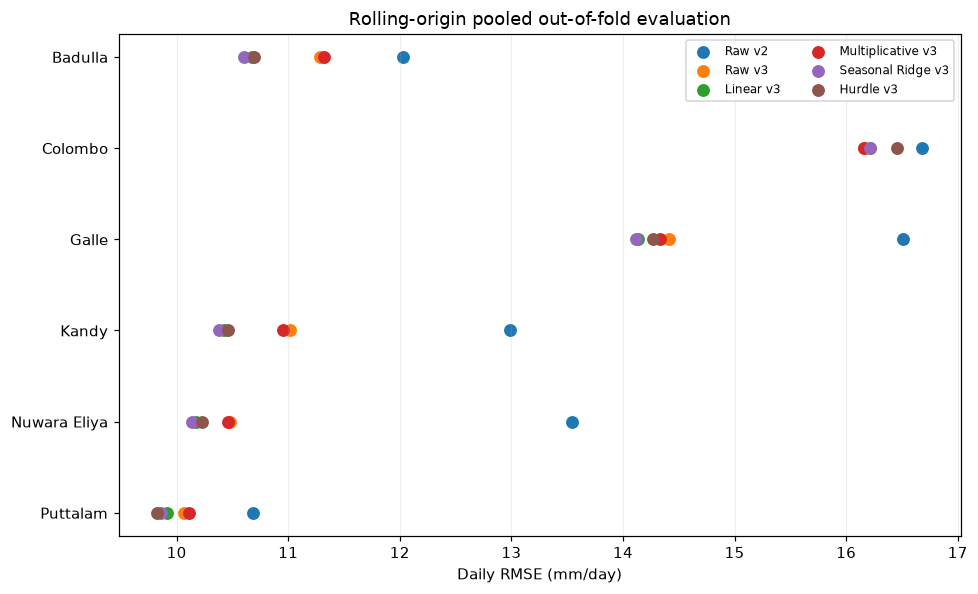

In [11]:
rows=[]; fold_rows=[]
for (station,model),a in predictions.groupby(['Station','Model'],sort=False):
    g=a.Gauge_mm_day.to_numpy(float);p=a.Prediction_mm_day.to_numpy(float)
    scores=rainfall_scores(g,p)
    occurrence = (a.Wet_probability.to_numpy(float)>=0.5).astype(float)*WET_THRESHOLD if model=='Hurdle v3' else p
    wet=wetday_scores(g,occurrence); heavy=heavy_scores(g,p)
    rows.append({'Station':station,'Model':model,**scores,**wet,**heavy})
    for fold,sub in a.groupby('Fold'):
        fold_rows.append({'Station':station,'Model':model,'Fold':fold,**rainfall_scores(sub.Gauge_mm_day,sub.Prediction_mm_day)})
daily=pd.DataFrame(rows)
fold_metrics=pd.DataFrame(fold_rows)
raw_ref=daily[daily.Model=='Raw v3'][['Station','RMSE']].rename(columns={'RMSE':'Raw_v3_RMSE'})
daily=daily.merge(raw_ref,on='Station',validate='many_to_one')
daily['RMSE_improvement_percent']=100*(daily.Raw_v3_RMSE-daily.RMSE)/daily.Raw_v3_RMSE
daily.to_csv(TABDIR/'04_daily_model_comparison.csv',index=False)
fold_metrics.to_csv(TABDIR/'05_foldwise_daily_metrics.csv',index=False)
display(daily[['Station','Model','n','RMSE','MAE','Bias','Pearson_r','POD','FAR','CSI','n_heavy','Heavy_RMSE','RMSE_improvement_percent']].round(3))
fig,ax=plot_metric_dotplot(daily,save_as='01_daily_RMSE_model_dotplot');plt.show()

In [27]:

# ============================================================
# NOTEBOOK 03 — WET-DAY THRESHOLD COMPARISON
# Rolling-origin validation: 1987–1994
# ============================================================

def compare_hurdle_wetday_rules(pred, probability_threshold=0.5):
    rows = []

    for station in STATIONS:
        s = pred[pred["Station"] == station]

        # Reference: raw CHIRPS v3 RNL
        raw = s[s["Model"] == "Raw v3"].sort_values("Date")

        # Calibrated hurdle predictions
        hurdle = s[s["Model"] == "Hurdle v3"].sort_values("Date")

        # Verify exact date matching
        assert np.array_equal(
            raw["Date"].to_numpy(),
            hurdle["Date"].to_numpy()
        )

        gauge = hurdle["Gauge_mm_day"].to_numpy(float)
        amount = hurdle["Prediction_mm_day"].to_numpy(float)
        probability = hurdle["Wet_probability"].to_numpy(float)

        rules = {
            "Raw v3: amount >= 1 mm/day":
                raw["Prediction_mm_day"].to_numpy(float),

            "Hurdle: amount >= 1 mm/day":
                amount,

            "Hurdle: probability >= 0.5":
                (probability >= probability_threshold).astype(float)
                * WET_THRESHOLD
        }

        for rule, predicted in rules.items():
            scores = wetday_scores(
                gauge,
                predicted,
                threshold=WET_THRESHOLD
            )

            rows.append({
                "Station": station,
                "Rule": rule,
                "n_days": len(gauge),
                **scores
            })

    return pd.DataFrame(rows)


wet_rule_comparison = compare_hurdle_wetday_rules(
    predictions
)

display(wet_rule_comparison.round(3))

wet_rule_comparison.to_csv(
    TABDIR / "Hurdle_wetday_threshold_comparison.csv",
    index=False
)


,Station,Rule,n_days,Hits,Misses,False_alarms,Correct_negatives,POD,FAR,CSI
0,Badulla,Raw v3: amount >= 1 mm/day,2918,801,207,727,1183,0.795,0.476,0.462
1,Badulla,Hurdle: amount >= 1 mm/day,2918,1008,0,1910,0,1.000,0.655,0.345
2,Badulla,Hurdle: probability >= 0.5,2918,444,564,190,1720,0.440,0.300,0.371
3,Colombo,Raw v3: amount >= 1 mm/day,2897,961,123,881,932,0.887,0.478,0.489
4,Colombo,Hurdle: amount >= 1 mm/day,2897,1084,0,1813,0,1.000,0.626,0.374
5,Colombo,Hurdle: probability >= 0.5,2897,473,611,155,1658,0.436,0.247,0.382
6,Galle,Raw v3: amount >= 1 mm/day,2913,956,254,758,945,0.790,0.442,0.486
7,Galle,Hurdle: amount >= 1 mm/day,2913,1210,0,1703,0,1.000,0.585,0.415
8,Galle,Hurdle: probability >= 0.5,2913,569,641,176,1527,0.470,0.236,0.411
9,Kandy,Raw v3: amount >= 1 mm/day,2921,938,212,750,1021,0.816,0.444,0.494


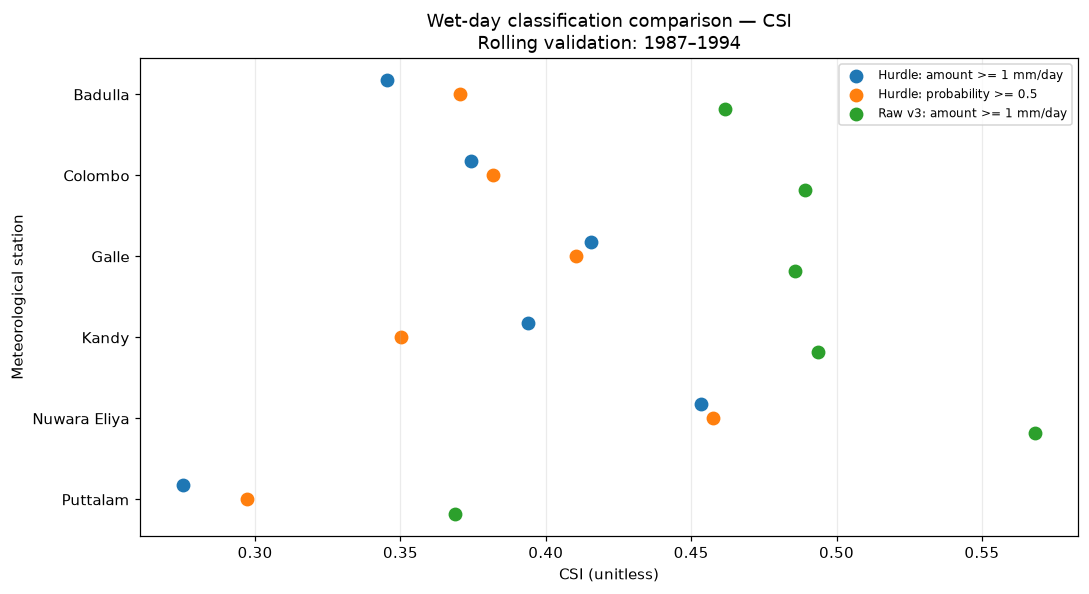

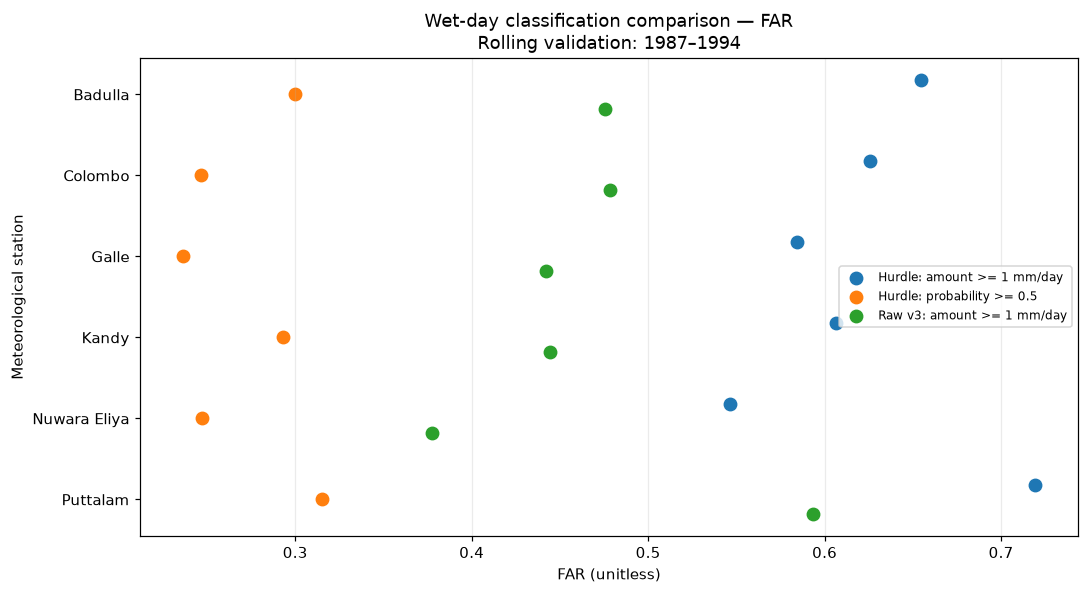

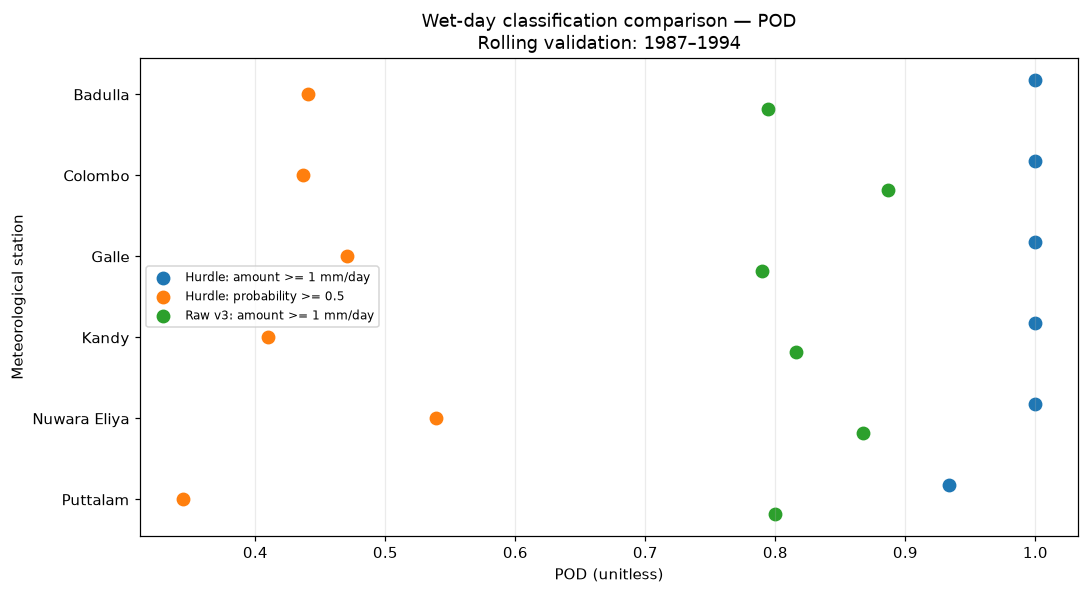

In [29]:
#reusable visulaization

def plot_hurdle_rule_comparison(
    results,
    metric="CSI",
    save_as=None
):
    pivot = results.pivot(
        index="Station",
        columns="Rule",
        values=metric
    ).reindex(STATIONS)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    y = np.arange(len(pivot))

    offsets = np.linspace(-0.18, 0.18, len(pivot.columns))

    for offset, rule in zip(offsets, pivot.columns):
        ax.scatter(
            pivot[rule],
            y + offset,
            label=rule,
            s=65
        )

    ax.set_yticks(y)
    ax.set_yticklabels([
        s.replace("Nuwaraeliya", "Nuwara Eliya")
        for s in pivot.index
    ])
    ax.invert_yaxis()

    ax.set_xlabel(f"{metric} (unitless)")
    ax.set_ylabel("Meteorological station")
    ax.set_title(
        f"Wet-day classification comparison — {metric}\n"
        "Rolling validation: 1987–1994"
    )

    ax.grid(axis="x", alpha=0.25)
    ax.legend(
        loc="best",
        fontsize=8
    )

    fig.tight_layout()

    if save_as:
        save_figure(fig, save_as)

    return fig, ax


# CSI: higher is better
fig, ax = plot_hurdle_rule_comparison(
    wet_rule_comparison,
    metric="CSI",
    save_as="09_hurdle_threshold_CSI"
)
plt.show()

# FAR: lower is better
fig, ax = plot_hurdle_rule_comparison(
    wet_rule_comparison,
    metric="FAR",
    save_as="10_hurdle_threshold_FAR"
)
plt.show()

# POD: higher is better
fig, ax = plot_hurdle_rule_comparison(
    wet_rule_comparison,
    metric="POD",
    save_as="11_hurdle_threshold_POD"
)
plt.show()


### Wet-Day Classification Sensitivity Analysis

**Research question:** How does the choice of wet-day classification rule affect the rainfall-detection performance of the Logistic–Gamma hurdle model compared with raw CHIRPS v3 RNL?

**Methodology:** Wet-day classification was evaluated using out-of-fold predictions from four expanding-window validation folds covering 1987–1994. A day was considered wet when observed gauge rainfall was at least **1 mm/day**. Three prediction rules were compared on identical station–date observations:

1. **Raw CHIRPS v3 RNL:** Predicted rainfall ≥ 1 mm/day.
2. **Hurdle rainfall-amount rule:** Predicted expected rainfall ≥ 1 mm/day.
3. **Hurdle probability rule:** Predicted probability of a wet day ≥ 0.5.

Detection performance was assessed using the Probability of Detection (POD), False Alarm Ratio (FAR), and Critical Success Index (CSI).

#### Results and interpretation

**Critical Success Index (CSI):**

Raw CHIRPS v3 RNL achieved the highest CSI at all six stations. Its CSI ranged from 0.369 at Puttalam to 0.568 at Nuwara Eliya.

The hurdle model produced lower CSI under both classification rules. For example, at Kandy, raw CHIRPS v3 achieved a CSI of 0.494, compared with 0.394 for the hurdle amount-threshold rule and 0.350 for the probability-threshold rule.

These results indicate that neither hurdle classification rule improved the overall balance between correctly detected rainfall events, missed events, and false alarms relative to raw CHIRPS v3 RNL.

**Probability of Detection (POD):**

The hurdle amount-threshold rule achieved POD = 1.000 at five stations, with Puttalam achieving 0.934. However, this high detection rate was accompanied by excessive false rainfall predictions.

In contrast, the hurdle probability-threshold rule produced lower POD values, ranging from 0.344 at Puttalam to 0.539 at Nuwara Eliya, indicating that many observed wet days were classified as dry.

**False Alarm Ratio (FAR):**

The probability-threshold rule consistently produced the lowest FAR across the six stations. For example, at Colombo, FAR decreased from 0.478 for raw CHIRPS v3 RNL to 0.247 for the hurdle probability rule.

However, this reduction came at the cost of decreased rainfall detection: Colombo's POD decreased from 0.887 to 0.436.

The hurdle amount-threshold rule generally produced the highest FAR, indicating substantial overprediction of wet-day occurrence.

#### Scientific explanation

The Logistic–Gamma hurdle model estimates both the probability of rainfall occurrence and the conditional intensity of rainfall. Its expected rainfall amount is calculated as the product of these two components.

Therefore, applying a 1 mm/day threshold to the expected rainfall amount is not equivalent to applying a 0.5 threshold to the estimated wet-day probability.

The amount-threshold rule tended to classify too many days as wet, whereas the probability-threshold rule was more conservative and missed a substantial fraction of observed rainfall events.

This illustrates the trade-off between rainfall detection sensitivity and false-alarm control.

#### Conclusion

The wet-day classification sensitivity analysis indicates that **raw CHIRPS v3 RNL provides better overall wet-day classification performance than the tested Logistic–Gamma hurdle rules**, based on CSI, at all six stations during rolling-origin validation.

Although the hurdle model reduced daily rainfall RMSE at selected stations, these improvements did not translate into superior rainfall-occurrence classification.

The results demonstrate that **optimizing rainfall-amount prediction does not necessarily optimize rainfall occurrence detection**.

Neither the 1 mm/day expected-amount threshold nor the fixed 0.5 probability threshold should be considered universally optimal. Further threshold tuning would require training-only or nested validation to avoid optimistic performance estimates.

Consequently, the hurdle model should not be selected solely on its daily RMSE performance, and raw CHIRPS v3 RNL remains an important wet-day detection baseline.

is produces three plots that answer different scientific questions:
- CSI: Which rule balances hits, misses and false alarms best?
- FAR: Which rule produces fewer false rainfall predictions?
- POD: Which rule detects more observed rainy days?
All three should be interpreted together.
The value 0.5 is a standard fixed decision threshold, but it is not necessarily the optimal threshold for rainfall occurrence.

Later, we can investigate thresholds such as 0.2–0.8. However, we must choose a threshold using training data or nested validation, not select the threshold that happens to produce the highest CSI on the same validation folds being reported.

For Notebook 03, comparing the two predefined decision rules is sufficient.

## 6 · Reusable improvement / diagnostic figures

The plots are functions. You can call them for any station without rerunning data extraction. The *fold-level* plot helps identify improvements that are inconsistent across historical periods. Small numbers of folds are **not** confidence intervals.

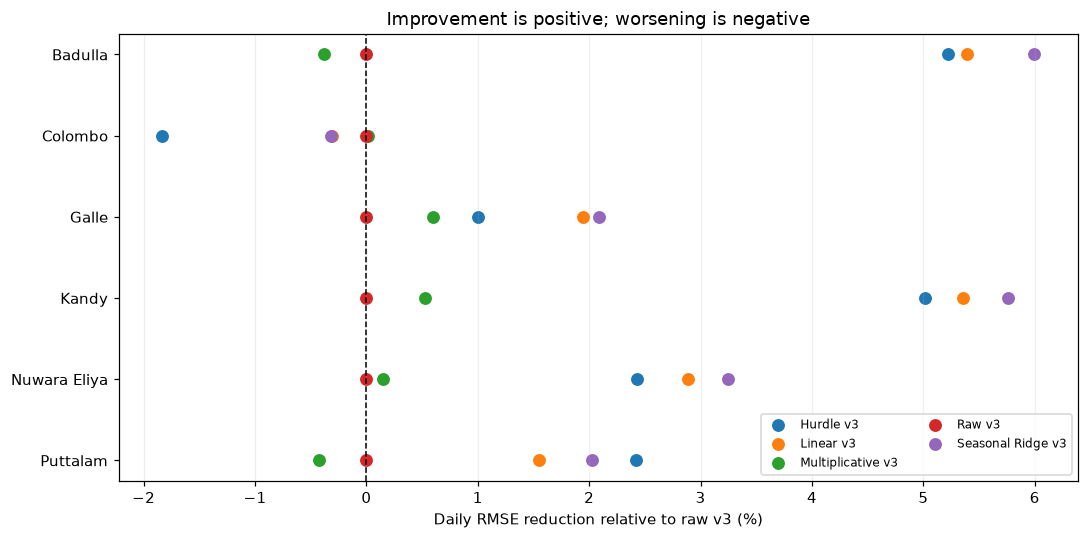

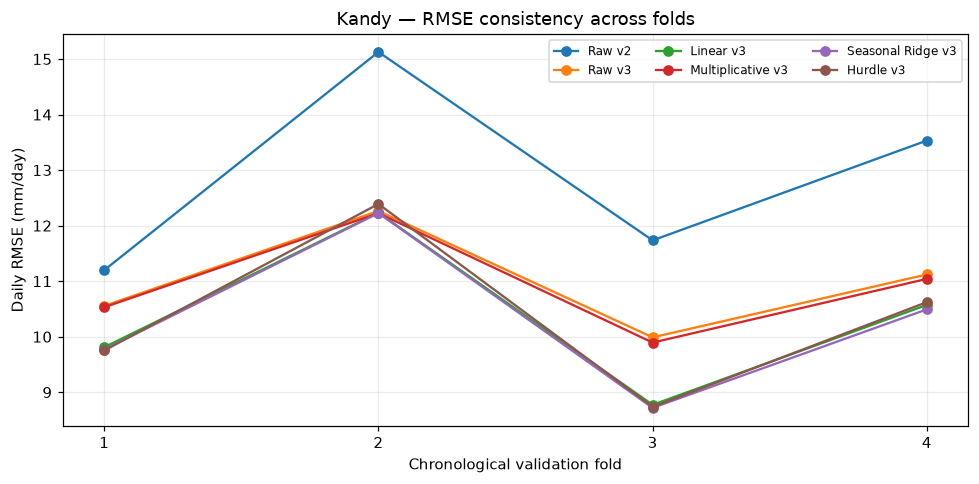

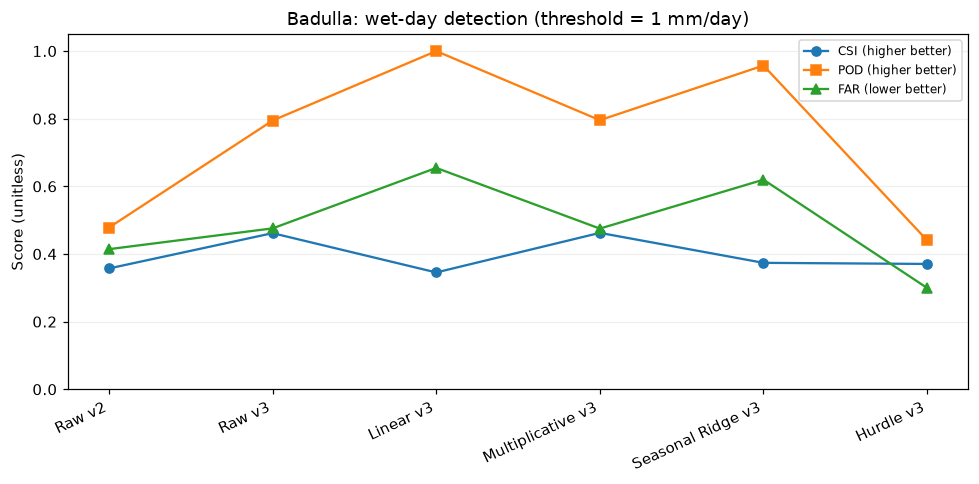

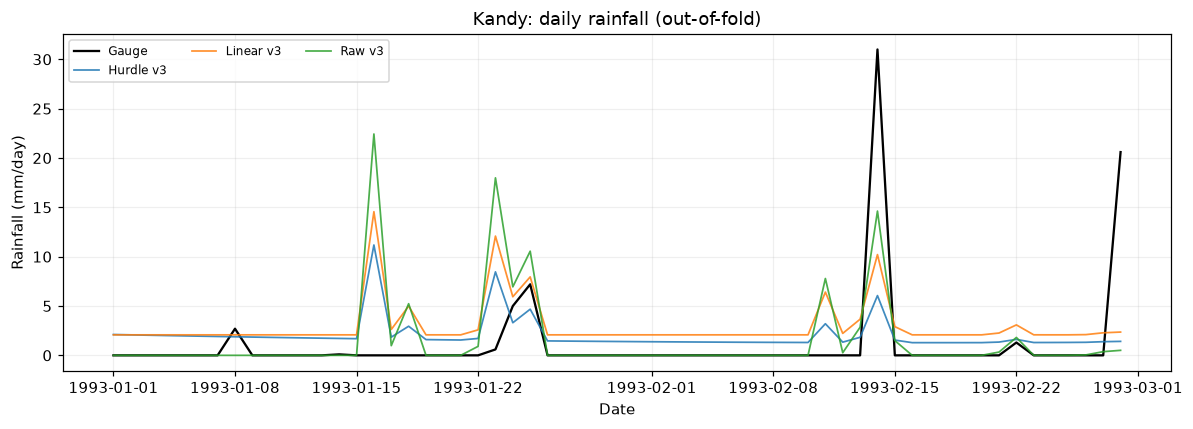

In [13]:
def plot_fold_rmse(fold_scores, station='Kandy', save_as=None):
    a=fold_scores[fold_scores.Station==station]
    pivot=a.pivot(index='Fold',columns='Model',values='RMSE')
    fig,ax=plt.subplots(figsize=(9,4.5))
    for model in MODELS:
        ax.plot(pivot.index,pivot[model],marker='o',label=model)
    ax.set(xticks=[1,2,3,4],xlabel='Chronological validation fold',ylabel='Daily RMSE (mm/day)',
           title=f'{station} — RMSE consistency across folds')
    ax.grid(alpha=.25);ax.legend(ncol=3,fontsize=8);fig.tight_layout()
    if save_as: save_figure(fig,save_as)
    return fig,ax

def plot_wet_skill(scores, station='Kandy', save_as=None):
    a=scores[scores.Station==station].set_index('Model').reindex(MODELS)
    fig,ax=plt.subplots(figsize=(9,4.5)); x=np.arange(len(a))
    ax.plot(x,a.CSI,'o-',label='CSI (higher better)')
    ax.plot(x,a.POD,'s-',label='POD (higher better)')
    ax.plot(x,a.FAR,'^-',label='FAR (lower better)')
    ax.set_xticks(x,a.index,rotation=25,ha='right');ax.set_ylabel('Score (unitless)')
    ax.set_title(f'{station}: wet-day detection (threshold = 1 mm/day)')
    ax.set_ylim(0,1.05);ax.grid(axis='y',alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_rmse_improvement(scores, save_as=None):
    d=scores[scores.Model!='Raw v2'].copy()
    fig,ax=plt.subplots(figsize=(10,5))
    for model,part in d.groupby('Model'):
        y=[STATIONS.index(s) for s in part.Station]
        ax.scatter(part.RMSE_improvement_percent,y,label=model,s=55)
    ax.axvline(0,color='black',ls='--',lw=1)
    ax.set_yticks(range(len(STATIONS)),[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set(xlabel='Daily RMSE reduction relative to raw v3 (%)',title='Improvement is positive; worsening is negative')
    ax.grid(axis='x',alpha=.2);ax.legend(ncol=2,fontsize=8);fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

fig,ax=plot_rmse_improvement(daily,save_as='02_RMSE_improvement_percent');plt.show()
fig,ax=plot_fold_rmse(fold_metrics,'Kandy',save_as='03_Kandy_fold_RMSE');plt.show()
fig,ax=plot_wet_skill(daily,'Badulla',save_as='04_Badulla_wet_day_tradeoffs');plt.show()
fig,ax=plot_station_predictions(predictions,'Kandy',start='1993-01-01',end='1993-02-28',
                                models=['Raw v3','Linear v3','Hurdle v3'],save_as='05_Kandy_daily_timeseries');plt.show()

## 7 · Do daily improvements preserve complete-month totals?

This is an **important falsification check** motivated by Notebook 01. Summing daily corrections is not equivalent to fitting a separate monthly model. Since validation blocks start and end at calendar-year boundaries, no month is cut by a fold boundary. The completeness rule excludes calendar months with missing gauge/satellite dates.

,Station,Model,n_complete_months,Monthly_RMSE_mm_month,Monthly_Bias_mm_month,Monthly_Pearson_r
0,Badulla,Hurdle v3,94,65.150,2.232,0.832
1,Badulla,Linear v3,94,65.509,6.983,0.862
2,Badulla,Multiplicative v3,94,56.750,8.253,0.864
3,Badulla,Raw v2,94,72.965,-4.042,0.772
4,Badulla,Raw v3,94,55.953,6.501,0.866
5,Badulla,Seasonal Ridge v3,94,59.312,7.997,0.854
6,Colombo,Hurdle v3,90,94.685,-34.994,0.893
7,Colombo,Linear v3,90,81.984,-26.312,0.908
8,Colombo,Multiplicative v3,90,73.969,-26.552,0.909
9,Colombo,Raw v2,90,93.223,-37.264,0.845


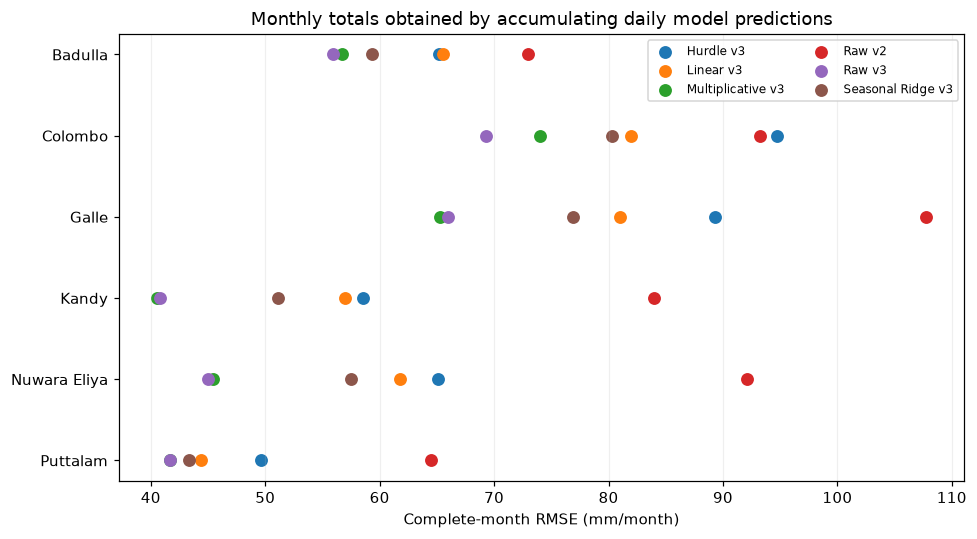

In [15]:
complete_months, monthly_scores=complete_month_scores(predictions)
complete_months.to_csv(TABDIR/'06_complete_monthly_out_of_fold_totals.csv',index=False)
monthly_scores.to_csv(TABDIR/'07_monthly_totals_from_daily_models.csv',index=False)
display(monthly_scores.round(3))

# Define generic dot plot explicitly for monthly-total scores
def plot_monthly_model_rmse(scores, save_as=None):
    fig,ax=plt.subplots(figsize=(9,5))
    for model,group in scores.groupby('Model'):
        y=[STATIONS.index(s) for s in group.Station]
        ax.scatter(group.Monthly_RMSE_mm_month,y,label=model,s=55)
    ax.set_yticks(range(6),[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set(xlabel='Complete-month RMSE (mm/month)',title='Monthly totals obtained by accumulating daily model predictions')
    ax.grid(axis='x',alpha=.2);ax.legend(fontsize=8,ncol=2);fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax
fig,ax=plot_monthly_model_rmse(monthly_scores,save_as='06_monthly_RMSE_from_daily_predictions');plt.show()

## 8 · Diagnostic plots: gauge vs prediction, signed residuals, ACF

These are **calibration diagnostics**, not tests of stationarity. Rainfall residuals can be skewed, heteroscedastic and temporally dependent. The autocorrelation plot is exploratory; an apparent pattern warrants later formal assessment and possibly model revision. It does *not* imply SARIMA automatically provides a better contemporaneous correction.

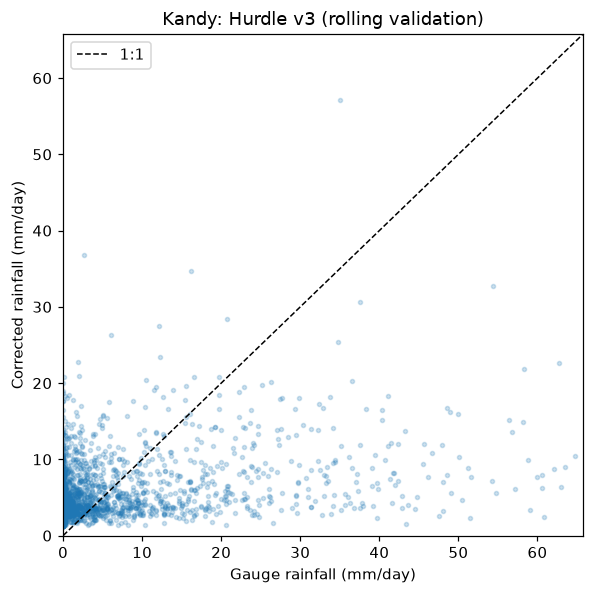

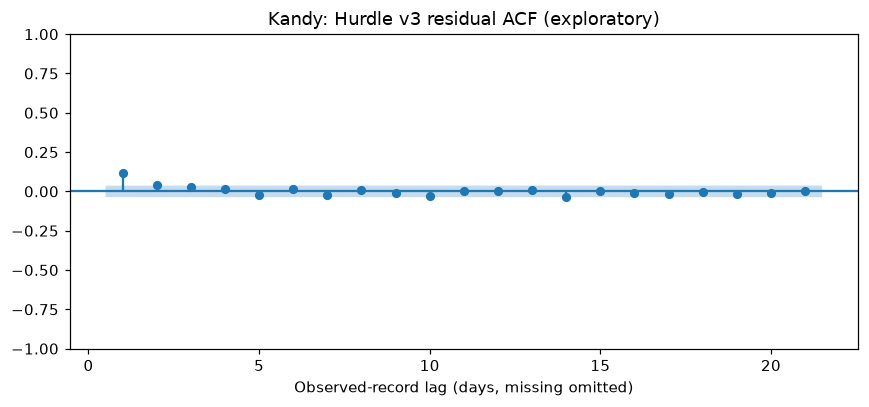

In [23]:
def plot_daily_scatter(pred,station='Kandy',model='Hurdle v3',save_as=None):
    a=pred[(pred.Station==station)&(pred.Model==model)]
    g=a.Gauge_mm_day.to_numpy(float);p=a.Prediction_mm_day.to_numpy(float)
    upper=max(np.quantile(g,.995),np.quantile(p,.995),1)
    fig,ax=plt.subplots(figsize=(5.5,5.5))
    ax.scatter(g,p,s=7,alpha=.22);ax.plot([0,upper],[0,upper],'k--',lw=1,label='1:1')
    ax.set(xlabel='Gauge rainfall (mm/day)',ylabel='Corrected rainfall (mm/day)',
           title=f'{station}: {model} (rolling validation)',xlim=(0,upper),ylim=(0,upper))
    ax.legend();fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

def plot_residual_acf(pred,station='Kandy',model='Hurdle v3',lags=21,save_as=None):
    from statsmodels.graphics.tsaplots import plot_acf
    a=pred[(pred.Station==station)&(pred.Model==model)].sort_values('Date').copy()
    # Avoid pretending a missing day is adjacent: explicitly reindex by calendar date.
    residual=(a.set_index('Date').Prediction_mm_day-a.set_index('Date').Gauge_mm_day)
    residual=residual.reindex(pd.date_range(a.Date.min(),a.Date.max(),freq='D'))
    fig,ax=plt.subplots(figsize=(8,3.8));plot_acf(residual.dropna(),lags=lags,ax=ax,zero=False)
    ax.set(title=f'{station}: {model} residual ACF (exploratory)',xlabel='Observed-record lag (days, missing omitted)')
    fig.tight_layout()
    if save_as:save_figure(fig,save_as)
    return fig,ax

fig,ax=plot_daily_scatter(predictions,station='Kandy',model='Hurdle v3',save_as='07_Kandy_hurdle_scatter');plt.show()
fig,ax=plot_residual_acf(predictions,station='Kandy',model='Hurdle v3',save_as='08_Kandy_hurdle_residual_ACF');plt.show()

## 9 · Provisional best daily model per station — development data only

Choose models by **pooled out-of-fold RMSE** on 1987–1994 dates, **not** by examining the 1995–2000 test period. Use the lowest-error candidate as a provisional daily-RMSE choice; treat gains under 1% as effectively tied and prefer raw v3 (the simpler baseline). Also display its wet-day CSI, heavy-day RMSE and accumulated monthly-total RMSE. In the final Notebook 06 we will use predeclared robustness/simplicity rules and discuss uncertainty before making recommendations.

**Interpretation caution:** The four folds use overlapping training sets. Model results may be dependent, and the best model in a short historical period may not generalize. This is an exploratory stationwise selection table, not six independently established significant winners.

In [19]:
candidate=daily[daily.Model!='Raw v2'].copy()
# Predeclared simplicity tie rule: if the best model improves <1% over raw v3, keep raw v3.
provisional_rows=[]
for station in STATIONS:
    a=candidate[candidate.Station==station].sort_values(['RMSE','Model'])
    choice=a.iloc[0]
    if choice.RMSE_improvement_percent < 1.0:
        choice=a.loc[a.Model.eq('Raw v3')].iloc[0]
    provisional_rows.append(choice)
provisional=pd.DataFrame(provisional_rows).reset_index(drop=True)
provisional=provisional.merge(monthly_scores[['Station','Model','Monthly_RMSE_mm_month','n_complete_months']],
                              on=['Station','Model'],how='left',validate='one_to_one')
cols=['Station','Model','n','RMSE','Raw_v3_RMSE','RMSE_improvement_percent','MAE',
      'Pearson_r','CSI','FAR','n_heavy','Heavy_RMSE','Monthly_RMSE_mm_month','n_complete_months']
display(provisional[cols].round(3))
provisional[cols].to_csv(TABDIR/'08_provisional_best_station_models_DEVELOPMENT_ONLY.csv',index=False)
print('NOTE: these are development-period candidates, not historical-test-confirmed winners.')

,Station,Model,n,RMSE,Raw_v3_RMSE,RMSE_improvement_percent,MAE,Pearson_r,CSI,FAR,n_heavy,Heavy_RMSE,Monthly_RMSE_mm_month,n_complete_months
0,Badulla,Seasonal Ridge v3,2918,10.604,11.281,5.997,5.538,0.422,0.374,0.620,163,37.810,59.312,94
1,Colombo,Raw v3,2897,16.162,16.162,0.000,6.786,0.453,0.489,0.478,219,52.553,69.333,90
2,Galle,Seasonal Ridge v3,2913,14.114,14.415,2.085,6.885,0.454,0.432,0.566,207,47.821,76.932,94
3,Kandy,Seasonal Ridge v3,2921,10.380,11.014,5.756,5.687,0.435,0.403,0.597,164,37.283,51.078,95
4,Nuwaraeliya,Seasonal Ridge v3,2915,10.137,10.478,3.249,5.393,0.443,0.499,0.498,158,37.089,57.539,89
5,Puttalam,Hurdle v3,2912,9.824,10.067,2.419,3.985,0.430,0.297,0.315,114,44.713,49.605,92


NOTE: these are development-period candidates, not historical-test-confirmed winners.


## 10 · Scientific conclusions: complete only after inspecting outputs

Use the outputs to answer these *without relying on a single metric*:

1. Which model has lowest **out-of-fold daily RMSE** at each station? What is the difference in **mm/day** and **%** from raw v3?
2. Does a positive **linear intercept** cause spurious predicted wet days? Compare `FAR` and `CSI` between the simple linear correction and Hurdle.
3. Does the Hurdle improve the *occurrence* metrics without necessarily improving *amount* RMSE? State both.
4. Do monthly accumulated totals worsen under any daily model? Report **mm/month** and complete-month counts.
5. On gauge-defined heavy rainfall days ≥25 mm/day, do models underpredict? Compare signed heavy bias and heavy RMSE without using gauge heavy-day labels as model inputs.
6. Are model rankings stable across the four validation folds? If not, describe them as uncertain.
7. Explicitly distinguish: station-specific temporal calibration here vs **leave-one-station-out** spatial transfer in Notebook 05.

**Suggested template:** “On the 1987–1994 expanding-window development folds, [model] achieved the lowest pooled daily RMSE at [station], reducing RMSE from [raw] to [model] mm/day ([percentage]%). However, its wet-day CSI was [value], and its complete-month total RMSE was [value] mm/month compared with [raw]. Therefore, its suitability depends on the target rainfall property; this is a development-period finding, not a pristine independent-test confirmation.”

### Methodological limitations

- CHIRPS grid cells are not identical to gauge-point supports; measurement-day definitions can differ.
- CHIRPS incorporates gauge information, so source product–gauge independence is not assured.
- A two-part model conditions positive intensity on ≥1 mm/day: observations below threshold are treated as not wet; this is a modelling convention, not exact physics.
- We did **not** optimize every model, use ERA5/terrain predictors, or compare monthly-specific calibration: those are planned for Notebooks 04–05.
- Earlier project work inspected 1995–2000; the final evaluation should transparently acknowledge this.

### Core references

1. Funk et al. (2015). *The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes*. Scientific Data. https://doi.org/10.1038/sdata.2015.66
2. Hyndman & Athanasopoulos. *Forecasting: Principles and Practice* (3rd ed.), chronological resampling and forecast evaluation. https://otexts.com/fpp3/
3. scikit-learn, `GammaRegressor` documentation (positive response, log link). https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.GammaRegressor.html
4. Google Earth Engine CHIRPS v2 dataset catalogue. https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY
5. Google Earth Engine CHIRPS v3 RNL catalogue. https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL
6. University of Colombo PH3043 supplied laboratory brief (compulsory daily validation, wet-day statistics, monthly comparisons, training-only simple correction).

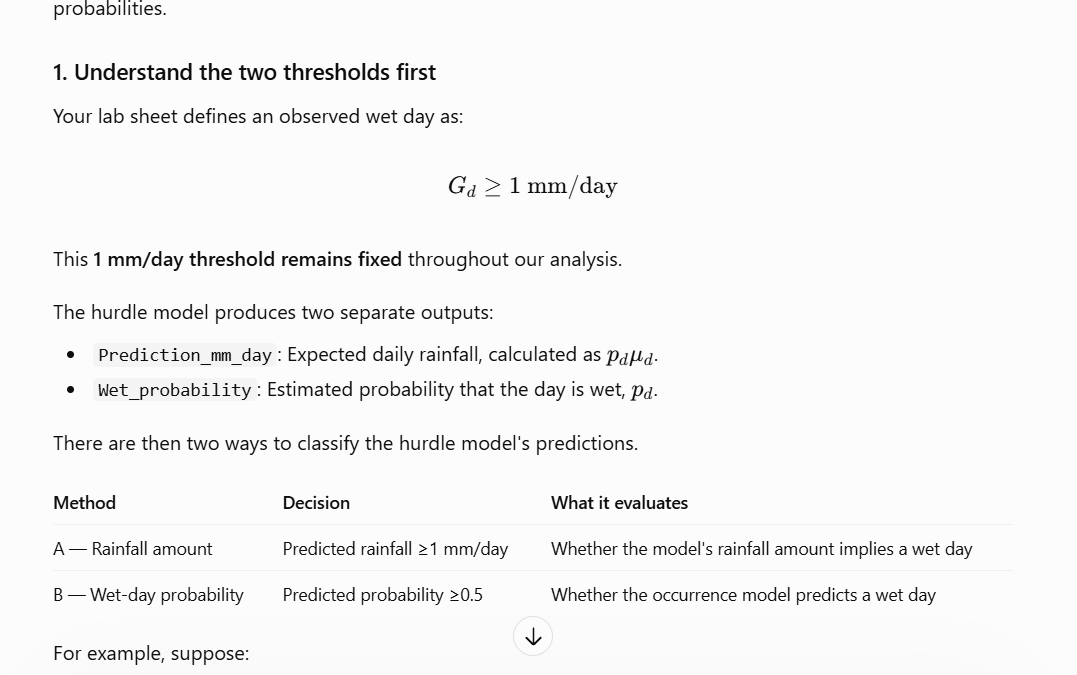

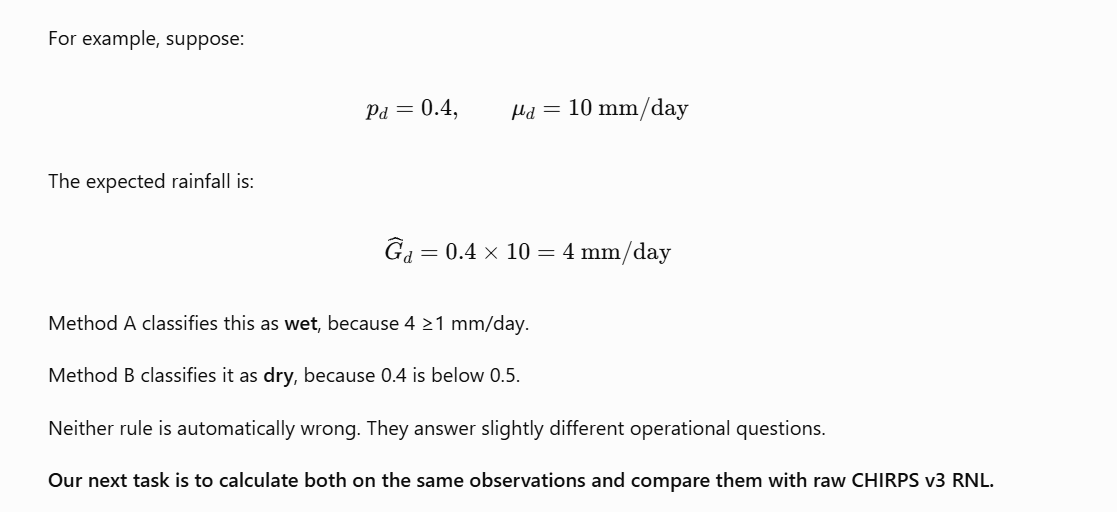

### Final Conclusion — Daily Rainfall Calibration

Daily rainfall calibration was investigated using raw CHIRPS v2 and v3 RNL, linear regression, multiplicative correction, seasonal Ridge regression, and Logistic–Gamma hurdle modelling. Models were evaluated using four expanding-window validation folds over 1987–1994.

Seasonal Ridge regression reduced daily RMSE at several stations, with improvements of approximately 6.00% at Badulla, 5.76% at Kandy, 3.25% at Nuwara Eliya, and 2.09% at Galle relative to raw CHIRPS v3 RNL. The Logistic–Gamma hurdle model achieved a 2.42% reduction at Puttalam, while raw CHIRPS v3 RNL remained competitive at Colombo.

However, improvements in daily RMSE did not consistently translate into better rainfall characteristics. At Kandy, seasonal Ridge regression worsened wet-day CSI, heavy-rainfall RMSE, and accumulated monthly rainfall RMSE. The hurdle model also demonstrated sensitivity to the wet-day decision threshold. Raw CHIRPS v3 RNL achieved higher wet-day CSI than both tested hurdle classification rules at all six stations.

These results demonstrate that minimizing daily RMSE alone is insufficient for selecting a scientifically reliable rainfall correction. The preferred model depends on the evaluation objective, station, and rainfall characteristic.

**Conclusion:** Notebook 03 identifies promising daily calibration models, but these are provisional candidates rather than final recommendations. Their performance on accumulated rainfall motivates separate pentad and monthly calibration experiments.